# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [3]:
ROLL_NO = 1024170113
NAME = "Dilpreet Singh"

import nltk

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger",
            "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [4]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [5]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [6]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170113   Name: Dilpreet Singh   Fingerprint: AC8334F3   Tickets: 15

Ticket_ID                                                                                 Ticket_Text
      T01 Python was working yesterday before the assignment deadline. The same problem occurs again.
      T02                   E-mail is not working before the assignment deadline. Can you check this?
      T03                                       The LMS failed to open. It works on another computer.
      T04            I couldn't connect to the Python after resetting my password. Please resolve it.
      T05                                 VPN keeps disconnecting since yesterday. Please resolve it.
      T06                                             The Matlab is showing an error. This is urgent.
      T07                                                 The state-of-the-art lab (Lab-3) is closed.
      T08                                       The e-mail failed to open. Is there another soluti

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [7]:
# Q1: Apply the official preprocessing pipeline to every ticket.
from IPython.display import display

processed = {row.Ticket_ID: process_ticket(row.Ticket_Text)
             for row in df.itertuples(index=False)}
q1_rows = []
for ticket_id, result in processed.items():
    q1_rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": result["sentences"],
        "Tokens": result["tokens"],
        "Punctuation": result["punct"],
        "Stopwords": result["stops"],
        "Unique tokens": sorted(set(result["tokens"])),
        "Final tokens": result["final"],
    })

all_tokens = [t for result in processed.values() for t in result["tokens"]]
all_punct = [t for result in processed.values() for t in result["punct"]]
all_stops = [t for result in processed.values() for t in result["stops"]]
all_final = [t for result in processed.values() for t in result["final"]]
q1_rows.append({
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(x["sentences"]) for x in processed.values()),
    "Tokens": len(all_tokens),
    "Punctuation": len(all_punct),
    "Stopwords": len(all_stops),
    "Unique tokens": len(set(all_tokens)),
    "Final tokens": len(all_final),
})
q1_table = pd.DataFrame(q1_rows)
display(q1_table)


,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique tokens,Final tokens
0,T01,[Python was working yesterday before the assig...,"[python, was, working, yesterday, before, the,...","[., .]","[was, before, the, the, same, again]","[., again, assignment, before, deadline, occur...","[python, working, yesterday, assignment, deadl..."
1,T02,[E-mail is not working before the assignment d...,"[e-mail, is, not, working, before, the, assign...","[., ?]","[is, not, before, the, can, you, this]","[., ?, assignment, before, can, check, deadlin...","[e-mail, working, assignment, deadline, check]"
2,T03,"[The LMS failed to open., It works on another ...","[the, lms, failed, to, open, ., it, works, on,...","[., .]","[the, to, it, on]","[., another, computer, failed, it, lms, on, op...","[lms, failed, open, works, another, computer]"
3,T04,[I couldn't connect to the Python after resett...,"[i, could, n't, connect, to, the, python, afte...","[., .]","[i, to, the, after, my, it]","[., after, connect, could, i, it, my, n't, pas...","[could, n't, connect, python, resetting, passw..."
4,T05,"[VPN keeps disconnecting since yesterday., Ple...","[vpn, keeps, disconnecting, since, yesterday, ...","[., .]",[it],"[., disconnecting, it, keeps, please, resolve,...","[vpn, keeps, disconnecting, since, yesterday, ..."
5,T06,"[The Matlab is showing an error., This is urge...","[the, matlab, is, showing, an, error, ., this,...","[., .]","[the, is, an, this, is]","[., an, error, is, matlab, showing, the, this,...","[matlab, showing, error, urgent]"
6,T07,[The state-of-the-art lab (Lab-3) is closed.],"[the, state-of-the-art, lab, (, lab-3, ), is, ...","[(, ), .]","[the, is]","[(, ), ., closed, is, lab, lab-3, state-of-the...","[state-of-the-art, lab, lab-3, closed]"
7,T08,"[The e-mail failed to open., Is there another ...","[the, e-mail, failed, to, open, ., is, there, ...","[., ?]","[the, to, is, there]","[., ?, another, e-mail, failed, is, open, solu...","[e-mail, failed, open, another, solution]"
8,T09,[I couldn't connect to the Matlab during the l...,"[i, could, n't, connect, to, the, matlab, duri...","[., .]","[i, to, the, during, the, i, do, what]","[., changed, connect, could, do, during, i, kn...","[could, n't, connect, matlab, lab, n't, know, ..."
9,T10,[Server keeps disconnecting after resetting my...,"[server, keeps, disconnecting, after, resettin...","[., .]","[after, my]","[., after, disconnecting, help, keeps, my, pas...","[server, keeps, disconnecting, resetting, pass..."


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer: The final tokens can include fragments such as n't, 's, and ca. They come from contractions in the original tickets. NLTK's word_tokenize splits contractions into multiple tokens (for example, can't can become ca + n't). The pipeline lowercases tokens and removes punctuation and stopwords, but it does not rejoin contraction fragments or remove every fragment, so some remain in the final-token list.*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re
# Ordered alternatives keep compound numeric forms, identifiers and contact details intact.
email_pat = r"(?<![\w.+-])[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+(?![\w.-])"
url_pat = r"(?:https?://|www\.)[^\s<>]*[^\s<>.,;!?]"
phone_pat = r"(?<!\w)(?:\+91[ -]?)?(?:\d{5}[ -]?\d{5}|\d{4}[ -]\d{3}[ -]\d{4})(?!\w)"
number_pat = r"(?<!\w)(?:\+91[ -]?)?(?:\d{5}[ -]?\d{5}|\d{4}[ -]\d{3}[ -]\d{4})(?!\w)|(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.,])\d{1,3}(?:,\d{3})+(?!\w)|(?<![\w.,])\d+(?![\w.,])%?"
word_pat = r"(?u)\b[A-Za-z]+(?:['’-][A-Za-z]+)*\b"
long_word_pat = r"(?u)\b[A-Za-z]{6,}(?:['’-][A-Za-z]+)*\b"
capital_pat = r"\b[A-Z][a-zA-Z]*(?:['’-][A-Za-z]+)*\b"
vowel_pat = r"\b[AEIOUaeiou][A-Za-z]*(?:['’-][A-Za-z]+)*\b"

raw_texts = df["Ticket_Text"].tolist()
print("WORDS LONGER THAN 5 LETTERS:")
for tid, txt in zip(df.Ticket_ID, raw_texts):
    print(tid, re.findall(long_word_pat, txt))
print("\nALL NUMBERS (compound decimals/versions kept whole):")
for tid, txt in zip(df.Ticket_ID, raw_texts):
    print(tid, re.findall(number_pat, txt))
print("\nCAPITALIZED WORDS:")
for tid, txt in zip(df.Ticket_ID, raw_texts):
    print(tid, re.findall(capital_pat, txt))
print("\nWORDS STARTING WITH A VOWEL:")
for tid, txt in zip(df.Ticket_ID, raw_texts):
    print(tid, re.findall(vowel_pat, txt))

# Count capitalized matches and identify those occurring only at sentence starts.
capitalized_total = sum(len(re.findall(capital_pat, txt)) for txt in raw_texts)
sentence_initial = 0
for txt in raw_texts:
    # Capitalized first alphabetic word at the beginning or after sentence-ending punctuation.
    sentence_initial += len(re.findall(r"(?:^|[.!?]\s+)([A-Z][a-zA-Z]*(?:['’-][A-Za-z]+)*)", txt))
print(f"\nCapitalized word matches: {capitalized_total}")
print(f"Sentence-initial capitalized words: {sentence_initial}")
print(f"Capitalized words not sentence-initial (approx.): {capitalized_total - sentence_initial}")

print("\nREDACTED TEST LINES:")
for line in TEST_LINES:
    redacted = re.sub(email_pat, "<EMAIL>", line)
    redacted = re.sub(url_pat, "<URL>", redacted)
    redacted = re.sub(phone_pat, "<PHONE>", redacted)
    print(redacted)

WORDS LONGER THAN 5 LETTERS:
T01 ['Python', 'working', 'yesterday', 'before', 'assignment', 'deadline', 'problem', 'occurs']
T02 ['working', 'before', 'assignment', 'deadline']
T03 ['failed', 'another', 'computer']
T04 ["couldn't", 'connect', 'Python', 'resetting', 'password', 'Please', 'resolve']
T05 ['disconnecting', 'yesterday', 'Please', 'resolve']
T06 ['Matlab', 'showing', 'urgent']
T07 ['closed']
T08 ['failed', 'another', 'solution']
T09 ["couldn't", 'connect', 'Matlab', 'during', 'changed']
T10 ['Server', 'disconnecting', 'resetting', 'password', 'Please']
T11 ['uploaded']
T12 ['running', 'slowly', 'before', 'assignment', 'deadline', 'several']
T13 ['helpdesk', 'university']
T14 ['Nothing', 'nobody', 'replied']
T15 ['Student', 'portal', 'stopped', 'syncing', 'laptop', 'worked', 'yesterday']

ALL NUMBERS (compound decimals/versions kept whole):
T01 []
T02 []
T03 []
T04 []
T05 []
T06 []
T07 ['3']
T08 []
T09 []
T10 []
T11 ['95.5']
T12 []
T13 []
T14 []
T15 []

CAPITALIZED WORDS:
T01

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer: The exact count is calculated below from the ticket text. A capitalized word is counted as sentence-initial only when it is the first alphabetic word after the start of the ticket or after sentence-ending punctuation. Other capitalized words may be acronyms or proper names.*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [9]:
# Your code
# One RegexpTokenizer pattern. Specific multi-character forms come before general words.
from nltk.tokenize import RegexpTokenizer, word_tokenize

TOKEN_PATTERN = (
    r"https?://[^\s<>]*[^\s<>.,;!?]|www\.[^\s<>]*[^\s<>.,;!?]|"
    r"[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+|"
    r"\+91[ -]?(?:\d{5}[ -]?\d{5})|\d{5}[ -]\d{5}|\d{4}-\d{3}-\d{4}|"
    r"\d+(?:\.\d+)+%?|\d+(?:,\d{3})+%?|"
    r"[A-Za-z]+(?:['’-][A-Za-z]+)+|[A-Za-z]+(?:-[A-Za-z]+)+|"
    r"[A-Za-z]+|\d+|[^\w\s]"
)
my_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

print("CUSTOM TOKENIZER ON TEST_LINES:")
for line in TEST_LINES:
    print(my_tokenize(line))

print("\nCUSTOM TOKENIZER VS word_tokenize ON TICKETS:")
comparison = []
for row in df.itertuples(index=False):
    custom = my_tokenize(row.Ticket_Text)
    standard = word_tokenize(row.Ticket_Text)
    comparison.append({"Ticket_ID": row.Ticket_ID,
                       "Custom tokens": custom,
                       "word_tokenize": standard,
                       "Different?": custom != standard})
display(pd.DataFrame(comparison))
different_ticket_count = sum(x["Different?"] for x in comparison)
print(f"Tickets tokenized differently: {different_ticket_count} out of {len(df)}")


CUSTOM TOKENIZER ON TEST_LINES:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']

CUSTOM TOKENIZER VS word_tokenize ON TICKETS:


,Ticket_ID,Custom tokens,word_tokenize,Different?
0,T01,"[Python, was, working, yesterday, before, the,...","[Python, was, working, yesterday, before, the,...",False
1,T02,"[E-mail, is, not, working, before, the, assign...","[E-mail, is, not, working, before, the, assign...",False
2,T03,"[The, LMS, failed, to, open, ., It, works, on,...","[The, LMS, failed, to, open, ., It, works, on,...",False
3,T04,"[I, couldn't, connect, to, the, Python, after,...","[I, could, n't, connect, to, the, Python, afte...",True
4,T05,"[VPN, keeps, disconnecting, since, yesterday, ...","[VPN, keeps, disconnecting, since, yesterday, ...",False
5,T06,"[The, Matlab, is, showing, an, error, ., This,...","[The, Matlab, is, showing, an, error, ., This,...",False
6,T07,"[The, state-of-the-art, lab, (, Lab, -, 3, ), ...","[The, state-of-the-art, lab, (, Lab-3, ), is, ...",True
7,T08,"[The, e-mail, failed, to, open, ., Is, there, ...","[The, e-mail, failed, to, open, ., Is, there, ...",False
8,T09,"[I, couldn't, connect, to, the, Matlab, during...","[I, could, n't, connect, to, the, Matlab, duri...",True
9,T10,"[Server, keeps, disconnecting, after, resettin...","[Server, keeps, disconnecting, after, resettin...",False


Tickets tokenized differently: 5 out of 15


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer: The exact number of tickets tokenized differently is printed by the comparison cell above. Differences occur because the custom tokenizer deliberately keeps contractions, hyphenated expressions, decimals, version strings, URLs, emails and phone numbers together, whereas NLTK's standard word_tokenize generally splits several of these forms.*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [10]:
# Your code
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

unique_final = sorted(set(all_final))
porter = PorterStemmer()
lancaster = LancasterStemmer()
# The ticket vocabulary contains common inflectional endings; remove these suffixes
# only when at least one stem character remains.
regexp_stemmer = RegexpStemmer(r"(ing|edly|ed|ly|ies|s)$", min=3)
lemmatizer = WordNetLemmatizer()

# POS tagger works on a sequence; map Penn Treebank tags to WordNet POS labels.
tagged = pos_tag(unique_final)
def to_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

q4_rows = []
for word, tag in tagged:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, to_wordnet_pos(tag))
    if len({word, p, l, r, lemma}) > 1 and len({p, l, r, lemma}) > 1:
        q4_rows.append({"Word": word, "POS": tag, "Porter": p,
                        "Lancaster": l, "Regexp": r, "WordNet lemma": lemma})
q4_table = pd.DataFrame(q4_rows)
display(q4_table if not q4_table.empty else pd.DataFrame(columns=["Word", "POS", "Porter", "Lancaster", "Regexp", "WordNet lemma"]))

# Show examples from the actual generated vocabulary for the observation.
print("Potential over-stemming examples (Lancaster/Regexp differs substantially from the lemma):")
for row in q4_rows:
    if row["Lancaster"] != row["WordNet lemma"] and row["Porter"] != row["WordNet lemma"]:
        print(row)
print("Potential under-stemming examples (an inflected form remains different from its lemma):")
for row in q4_rows:
    if row["Porter"] == row["Word"] and row["WordNet lemma"] != row["Word"]:
        print(row)


,Word,POS,Porter,Lancaster,Regexp,WordNet lemma
0,another,DT,anoth,anoth,another,another
1,assignment,NN,assign,assign,assignment,assignment
2,changed,VBD,chang,chang,chang,change
3,closed,VBD,close,clos,clos,close
4,computer,NN,comput,comput,computer,computer
5,deadline,VB,deadlin,deadlin,deadline,deadline
6,error,NN,error,er,error,error
7,file,NN,file,fil,file,file
8,lms,NN,lm,lms,lm,lm
9,nobody,NN,nobodi,nobody,nobody,nobody


Potential over-stemming examples (Lancaster/Regexp differs substantially from the lemma):
{'Word': 'another', 'POS': 'DT', 'Porter': 'anoth', 'Lancaster': 'anoth', 'Regexp': 'another', 'WordNet lemma': 'another'}
{'Word': 'assignment', 'POS': 'NN', 'Porter': 'assign', 'Lancaster': 'assign', 'Regexp': 'assignment', 'WordNet lemma': 'assignment'}
{'Word': 'changed', 'POS': 'VBD', 'Porter': 'chang', 'Lancaster': 'chang', 'Regexp': 'chang', 'WordNet lemma': 'change'}
{'Word': 'computer', 'POS': 'NN', 'Porter': 'comput', 'Lancaster': 'comput', 'Regexp': 'computer', 'WordNet lemma': 'computer'}
{'Word': 'deadline', 'POS': 'VB', 'Porter': 'deadlin', 'Lancaster': 'deadlin', 'Regexp': 'deadline', 'WordNet lemma': 'deadline'}
{'Word': 'nothing', 'POS': 'NN', 'Porter': 'noth', 'Lancaster': 'noth', 'Regexp': 'noth', 'WordNet lemma': 'nothing'}
{'Word': 'please', 'POS': 'NN', 'Porter': 'pleas', 'Lancaster': 'pleas', 'Regexp': 'please', 'WordNet lemma': 'please'}
{'Word': 'resolve', 'POS': 'NN', 'Po

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer: Use the examples printed immediately above, because they are selected from the vocabulary generated for this roll number. Over-stemming occurs when a stemmer removes too much and produces an unnecessarily shortened or distorted stem (often visible with the aggressive Lancaster or chosen RegexpStemmer). Under-stemming occurs when related inflected forms are not reduced to the same base form; for example, a stemmer may leave a form unchanged while WordNet lemmatization converts it to its dictionary lemma. The table gives the exact words and outputs for this dataset*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Tokens,Unique tokens,TTR
0,S1,176,92,0.5227
1,S2,146,85,0.5822
2,S3,86,59,0.6860
3,S4,86,57,0.6628


TOP 10 WORDS — S1
[('.', 23), ('the', 12), ('is', 7), ('to', 4), ('it', 4), ('i', 4), ('yesterday', 3), ('before', 3), ('assignment', 3), ('deadline', 3)]

TOP 10 WORDS — S3
[('yesterday', 3), ('assignment', 3), ('deadline', 3), ('e-mail', 3), ("n't", 3), ('please', 3), ('python', 2), ('working', 2), ('failed', 2), ('open', 2)]


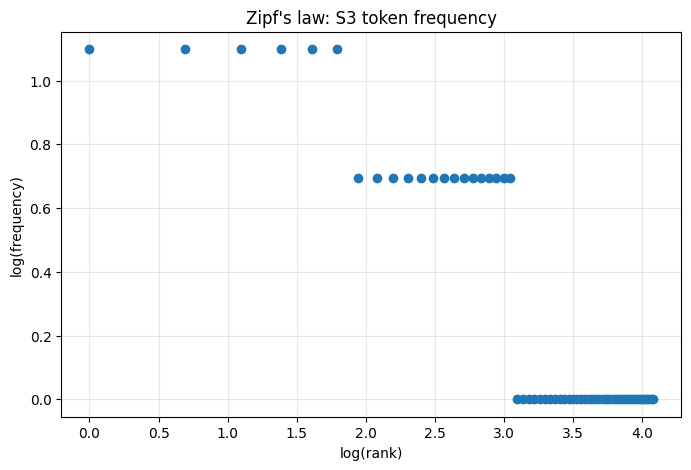

TOP 5 BIGRAMS — S1
[(('.', 'the'), 5), (('before', 'the'), 3), (('the', 'assignment'), 3), (('assignment', 'deadline'), 3), (('deadline', '.'), 3)]

TOP 5 BIGRAMS — S3
[(('assignment', 'deadline'), 3), (('failed', 'open'), 2), (('could', "n't"), 2), (("n't", 'connect'), 2), (('resetting', 'password'), 2)]


In [11]:
# Your code
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# S1: all word_tokenize tokens, including punctuation
S1 = [t.lower() for text in df.Ticket_Text for t in word_tokenize(text)]
# S2: remove punctuation tokens only
S2 = [t for t in S1 if not is_punct(t)]
# S3: official pipeline's final tokens (punctuation and English stopwords removed)
S3 = list(all_final)
# S4: Porter stems of S3
S4 = [porter.stem(t) for t in S3]

def corpus_stats(name, corpus):
    n_tokens = len(corpus)
    n_unique = len(set(corpus))
    ttr = n_unique / n_tokens if n_tokens else 0
    return {"Corpus": name, "Tokens": n_tokens,
            "Unique tokens": n_unique, "TTR": round(ttr, 4)}

stats = pd.DataFrame([corpus_stats("S1", S1), corpus_stats("S2", S2),
                      corpus_stats("S3", S3), corpus_stats("S4", S4)])
print("CORPUS STATISTICS")
display(stats)

print("TOP 10 WORDS — S1")
print(Counter(S1).most_common(10))
print("\nTOP 10 WORDS — S3")
print(Counter(S3).most_common(10))

freq = Counter(S3)
ranked = freq.most_common()
ranks = np.arange(1, len(ranked) + 1)
frequencies = np.array([count for _, count in ranked])
plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(frequencies), marker="o", linestyle="none")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf's law: S3 token frequency")
plt.grid(True, alpha=0.3)
plt.show()

print("TOP 5 BIGRAMS — S1")
print(Counter(zip(S1, S1[1:])).most_common(5))
print("\nTOP 5 BIGRAMS — S3")
print(Counter(zip(S3, S3[1:])).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer: TTR is the ratio of unique tokens to total tokens. From S1 to S4, punctuation and stopword removal reduce the total token count, while stemming merges some related word forms (for example, inflections may map to the same stem), reducing the number of unique types. Because both the numerator and denominator change, TTR may rise or fall; the printed statistics show the direction and magnitude for this roll-number-specific corpus.*